DATASET SOURCE:
https://www.statista.com/statistics/1092819/global-influencer-market-size/


Saving Influencer Marketing Messy & Cleaned data.xlsx to Influencer Marketing Messy & Cleaned data.xlsx
CLEANED INFLUENCER MARKETING DATASET


,Category,Item,Metric,Value,Unit,Source_Note
0,Market spend,2021,Global influencer marketing spend,14,USD billions,Illustrative figure from PDF chart
1,Market spend,2022,Global influencer marketing spend,16,USD billions,Illustrative figure from PDF chart
2,Market spend,2023,Global influencer marketing spend,21,USD billions,Illustrative figure from PDF chart
3,Market spend,2024,Global influencer marketing spend,24,USD billions,Illustrative figure from PDF chart
4,Market spend,2025,Global influencer marketing spend,NaN,USD billions,Illustrative figure from PDF chart
5,Market spend,2026,Global influencer marketing spend,33,USD billions,Illustrative figure from PDF chart
6,Influencer tier,Nano,Follower range,1k to 10k,followers,PDF tier benchmark
7,Influencer tier,Nano,Average engagement rate range,6–8,percent,PDF tier benchmark
8,Influencer tier,Micro,Follower range,"10,000–100,000",followers,PDF tier benchmark
9,Influencer tier,Micro,Average engagement rate range,3–6,percent,PDF tier benchmark



Dataset Shape: (34, 6)

Column Names: ['Category', 'Item', 'Metric', 'Value', 'Unit', 'Source_Note']

Missing Values in Each Column:
Category          0
Item              0
Metric            0
Value             2
Unit              0
Source_Note       0
Numeric_Value    12
dtype: int64

Cleaned Dataset:


,Category,Item,Metric,Value,Unit,Source_Note,Numeric_Value
0,Market spend,2021,Global influencer marketing spend,14,USD billions,Illustrative figure from PDF chart,14.0
1,Market spend,2022,Global influencer marketing spend,16,USD billions,Illustrative figure from PDF chart,16.0
2,Market spend,2023,Global influencer marketing spend,21,USD billions,Illustrative figure from PDF chart,21.0
3,Market spend,2024,Global influencer marketing spend,24,USD billions,Illustrative figure from PDF chart,24.0
4,Market spend,2025,Global influencer marketing spend,NaN,USD billions,Illustrative figure from PDF chart,NaN
5,Market spend,2026,Global influencer marketing spend,33,USD billions,Illustrative figure from PDF chart,33.0
6,Influencer tier,Nano,Follower range,1k to 10k,followers,PDF tier benchmark,NaN
7,Influencer tier,Nano,Average engagement rate range,6–8,percent,PDF tier benchmark,NaN
8,Influencer tier,Micro,Follower range,"10,000–100,000",followers,PDF tier benchmark,NaN
9,Influencer tier,Micro,Average engagement rate range,3–6,percent,PDF tier benchmark,NaN


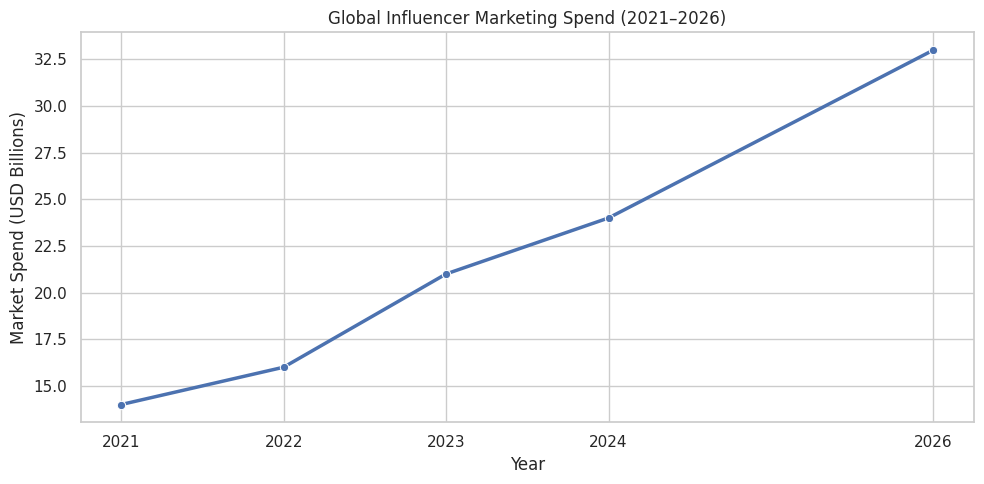

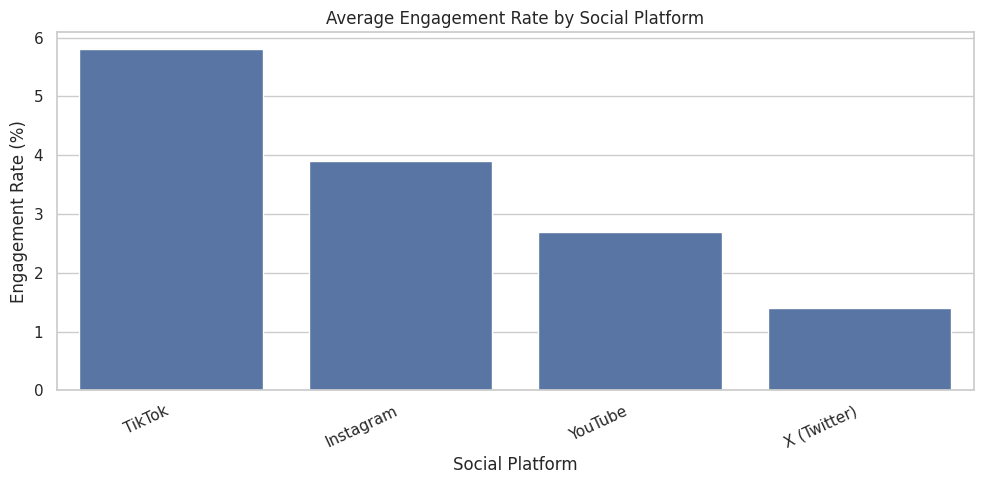

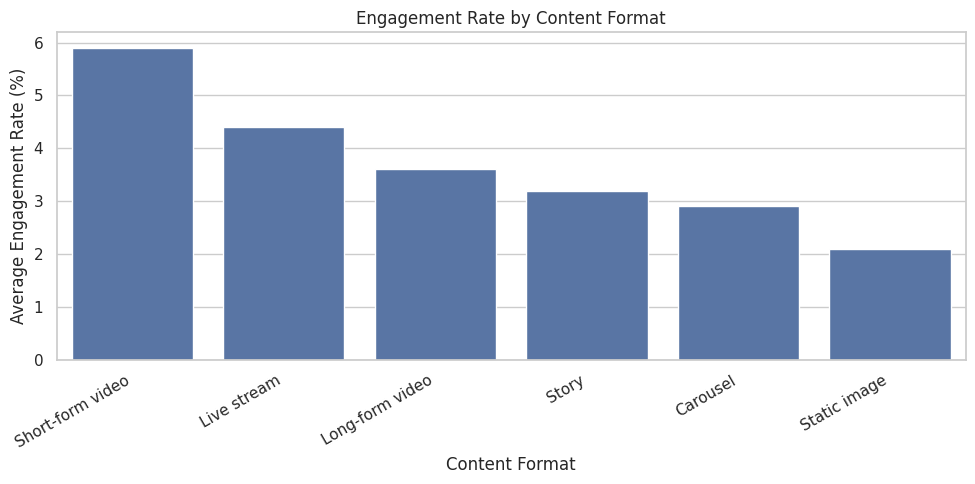

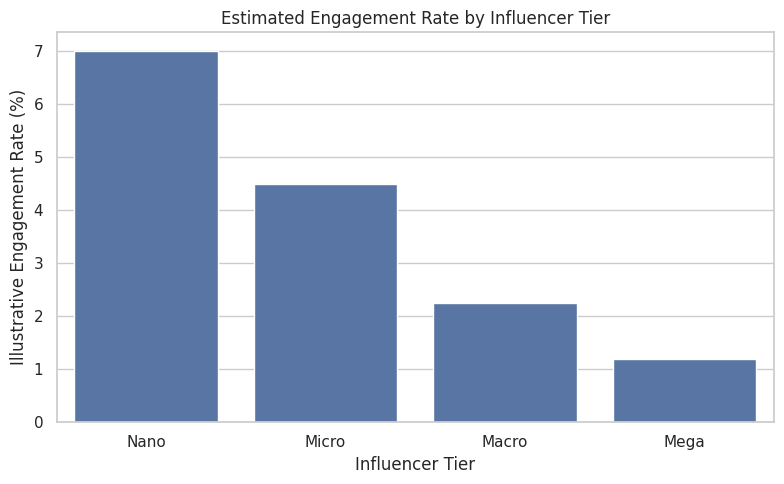

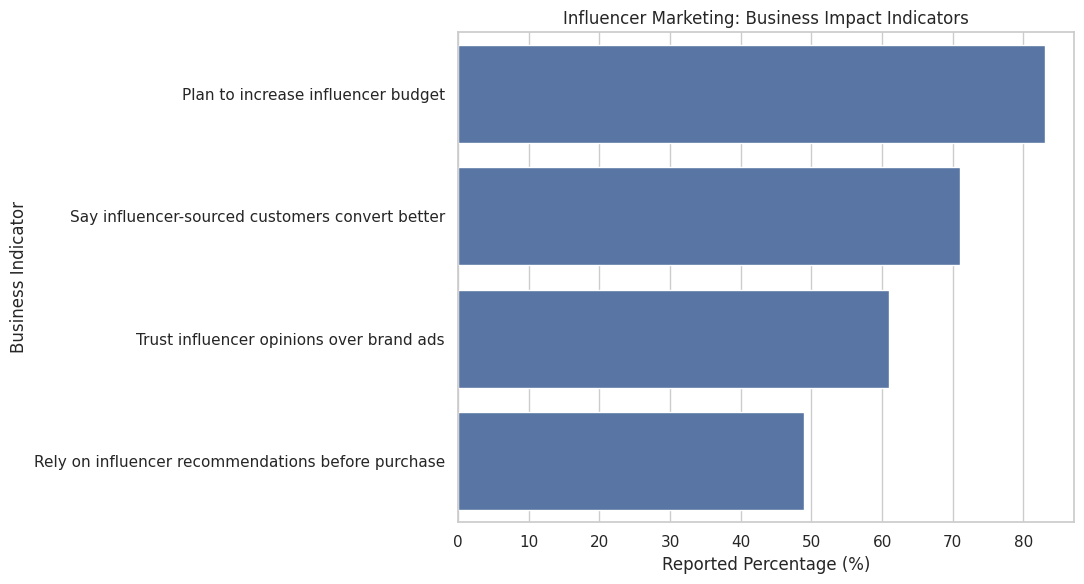

INFLUENCER MARKETING DATA SUMMARY

Total Records: 34
Total Categories: 5

Records by Category:


,Record Count
Category,
Influencer tier,8
Business impact,8
Market spend,6
Social platform,6
Content format,6



Dataset Source:
https://www.statista.com/statistics/1092819/global-influencer-market-size/

Visualization completed successfully!


In [1]:
# ============================================================
# SECTION 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")

# Dataset Source
DATASET_SOURCE = "https://www.statista.com/statistics/1092819/global-influencer-market-size/"

print("DATASET SOURCE:")
print(DATASET_SOURCE)


# ============================================================
# SECTION 2: UPLOAD AND READ THE EXCEL DATASET
# ============================================================

uploaded = files.upload()

file_name = next(iter(uploaded))

# Read the cleaned dataset from the Excel file
df = pd.read_excel(file_name, sheet_name="Cleaned data")

print("CLEANED INFLUENCER MARKETING DATASET")
print("=" * 50)
display(df)

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())


# ============================================================
# SECTION 3: BASIC DATA CLEANING
# ============================================================

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove unnecessary spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert Value column into a numeric column where possible
df["Numeric_Value"] = pd.to_numeric(df["Value"], errors="coerce")

# Correct fractional percentage values such as 0.039 to 3.9
# This applies only to percentage-based engagement metrics.
mask = (
    df["Metric"].str.contains("engagement rate", case=False, na=False)
    & df["Unit"].eq("percent")
    & df["Numeric_Value"].between(0, 1, inclusive="neither")
)

df.loc[mask, "Numeric_Value"] = df.loc[mask, "Numeric_Value"] * 100

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
display(df)


# ============================================================
# SECTION 4: VISUALIZE GLOBAL INFLUENCER MARKETING SPEND
# ============================================================

market = df[
    (df["Category"] == "Market spend")
    & (df["Metric"] == "Global influencer marketing spend")
].copy()

market["Year"] = pd.to_numeric(market["Item"], errors="coerce")
market["Numeric_Value"] = pd.to_numeric(
    market["Value"], errors="coerce"
)

market = market.dropna(subset=["Year", "Numeric_Value"])
market = market.sort_values("Year")

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=market,
    x="Year",
    y="Numeric_Value",
    marker="o",
    linewidth=2.5
)

plt.title("Global Influencer Marketing Spend (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Market Spend (USD Billions)")
plt.xticks(market["Year"].astype(int))
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 5: VISUALIZE SOCIAL PLATFORM ENGAGEMENT
# ============================================================

platforms = df[
    (df["Category"] == "Social platform")
    & (df["Metric"] == "Average post engagement rate")
].copy()

platforms["Numeric_Value"] = pd.to_numeric(
    platforms["Numeric_Value"], errors="coerce"
)

platforms = platforms.dropna(subset=["Numeric_Value"])

# Average duplicate platform records after percentage normalization
platforms = (
    platforms.groupby("Item", as_index=False)["Numeric_Value"]
    .mean()
    .sort_values("Numeric_Value", ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=platforms,
    x="Item",
    y="Numeric_Value"
)

plt.title("Average Engagement Rate by Social Platform")
plt.xlabel("Social Platform")
plt.ylabel("Engagement Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 6: VISUALIZE CONTENT FORMAT ENGAGEMENT
# ============================================================

content = df[df["Category"] == "Content format"].copy()

content["Numeric_Value"] = pd.to_numeric(
    content["Value"], errors="coerce"
)

content = content.dropna(subset=["Numeric_Value"])
content = content.sort_values("Numeric_Value", ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=content,
    x="Item",
    y="Numeric_Value"
)

plt.title("Engagement Rate by Content Format")
plt.xlabel("Content Format")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 7: VISUALIZE INFLUENCER TIER ENGAGEMENT
# ============================================================

tiers = df[
    (df["Category"] == "Influencer tier")
    & (df["Metric"] == "Average engagement rate range")
].copy()

# Approximate midpoints for ranges given in the source dataset.
# Mega tier is represented by 1.2% as an illustrative value below 1.5%.
tier_midpoints = {
    "Nano": 7.0,
    "Micro": 4.5,
    "Macro": 2.25,
    "Mega": 1.2
}

tiers["Estimated_Engagement"] = tiers["Item"].map(tier_midpoints)
tiers = tiers.dropna(subset=["Estimated_Engagement"])

plt.figure(figsize=(8, 5))

sns.barplot(
    data=tiers,
    x="Item",
    y="Estimated_Engagement",
    order=["Nano", "Micro", "Macro", "Mega"]
)

plt.title("Estimated Engagement Rate by Influencer Tier")
plt.xlabel("Influencer Tier")
plt.ylabel("Illustrative Engagement Rate (%)")
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 8: VISUALIZE BUSINESS IMPACT PERCENTAGES
# ============================================================

impact = df[
    (df["Category"] == "Business impact")
    & (df["Unit"] == "percent")
].copy()

impact["Numeric_Value"] = pd.to_numeric(
    impact["Value"], errors="coerce"
)

impact = impact.dropna(subset=["Numeric_Value"])

# Keep percentage-based business indicators only
impact = impact.sort_values("Numeric_Value", ascending=False)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=impact,
    x="Numeric_Value",
    y="Metric"
)

plt.title("Influencer Marketing: Business Impact Indicators")
plt.xlabel("Reported Percentage (%)")
plt.ylabel("Business Indicator")
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 9: DISPLAY SUMMARY STATISTICS
# ============================================================

print("INFLUENCER MARKETING DATA SUMMARY")
print("=" * 50)

print("\nTotal Records:", len(df))
print("Total Categories:", df["Category"].nunique())

print("\nRecords by Category:")
display(df["Category"].value_counts().rename("Record Count"))

print("\nDataset Source:")
print(DATASET_SOURCE)

print("\nVisualization completed successfully!")